In [1]:
import pandas as pd

# Load the three datasets
income_df = pd.read_csv('/content/hh_income_state (1).csv')
marriages_df = pd.read_csv('/content/marriages_state (1).csv')
schools_df = pd.read_csv('/content/schools_district (1).csv')

print("Household Income Dataset:", income_df.shape)
print("Marriage Dataset:", marriages_df.shape)
print("Schools Dataset:", schools_df.shape)

Household Income Dataset: (319, 4)
Marriage Dataset: (256, 5)
Schools Dataset: (4514, 6)


In [2]:
print("===== HOUSEHOLD INCOME =====")
display(income_df.head())

print("\n===== MARRIAGE =====")
display(marriages_df.head())

print("\n===== SCHOOLS =====")
display(schools_df.head())

===== HOUSEHOLD INCOME =====


,state,date,income_mean,income_median
0,Johor,1970-01-01,237,NaN
1,Johor,1974-01-01,382,269.0
2,Johor,1976-01-01,513,370.0
3,Johor,1979-01-01,731,518.0
4,Johor,1984-01-01,1065,793.0



===== MARRIAGE =====


,state,date,sex,abs,rate
0,Johor,2017-01-01,female,27308,27.59
1,Johor,2017-01-01,male,27626,25.82
2,Johor,2018-01-01,female,26806,26.70
3,Johor,2018-01-01,male,27153,25.20
4,Johor,2019-01-01,female,26574,26.40



===== SCHOOLS =====


,state,district,stage,type,date,schools
0,Malaysia,All Districts,primary,Sekolah Rendah Kerajaan,2017-01-01,7776
1,Malaysia,All Districts,primary,Sekolah Rendah Kerajaan,2018-01-01,7774
2,Malaysia,All Districts,primary,Sekolah Rendah Kerajaan,2019-01-01,7773
3,Malaysia,All Districts,primary,Sekolah Rendah Kerajaan,2020-01-01,7780
4,Malaysia,All Districts,primary,Sekolah Rendah Kerajaan,2021-01-01,7780


In [3]:
print("HOUSEHOLD INCOME YEARS:")
print(sorted(income_df['date'].str[:4].unique()))

print("\nMARRIAGE YEARS:")
print(sorted(marriages_df['date'].str[:4].unique()))

print("\nSCHOOLS YEARS:")
print(sorted(schools_df['date'].str[:4].unique()))

HOUSEHOLD INCOME YEARS:
['1970', '1974', '1976', '1979', '1984', '1987', '1989', '1992', '1995', '1997', '1999', '2002', '2004', '2007', '2009', '2012', '2014', '2016', '2019', '2020', '2022', '2024']

MARRIAGE YEARS:
['2017', '2018', '2019', '2020', '2021', '2022', '2023', '2024']

SCHOOLS YEARS:
['2017', '2018', '2019', '2020', '2021', '2022', '2023', '2024', '2025']


In [4]:
print("HOUSEHOLD INCOME - Missing Values")
print(income_df.isnull().sum())

print("\nMARRIAGE - Missing Values")
print(marriages_df.isnull().sum())

print("\nSCHOOLS - Missing Values")
print(schools_df.isnull().sum())

HOUSEHOLD INCOME - Missing Values
state             0
date              0
income_mean       0
income_median    11
dtype: int64

MARRIAGE - Missing Values
state    0
date     0
sex      0
abs      0
rate     1
dtype: int64

SCHOOLS - Missing Values
state       0
district    0
stage       0
type        0
date        0
schools     0
dtype: int64


In [5]:
print("HOUSEHOLD INCOME - Missing Median Income")
display(income_df[income_df['income_median'].isnull()])

print("\nMARRIAGE - Missing Marriage Rate")
display(marriages_df[marriages_df['rate'].isnull()])

HOUSEHOLD INCOME - Missing Median Income


,state,date,income_mean,income_median
0,Johor,1970-01-01,237,NaN
22,Kedah,1970-01-01,189,NaN
44,Kelantan,1970-01-01,151,NaN
66,Melaka,1970-01-01,265,NaN
88,Negeri Sembilan,1970-01-01,286,NaN
110,Pahang,1970-01-01,286,NaN
132,Perak,1970-01-01,254,NaN
154,Perlis,1970-01-01,140,NaN
176,Pulau Pinang,1970-01-01,292,NaN
238,Selangor,1970-01-01,421,NaN



MARRIAGE - Missing Marriage Rate


,state,date,sex,abs,rate
255,W.P. Putrajaya,2024-01-01,male,509,NaN


In [6]:
# Convert date columns into datetime format
income_df['date'] = pd.to_datetime(income_df['date'])
marriages_df['date'] = pd.to_datetime(marriages_df['date'])
schools_df['date'] = pd.to_datetime(schools_df['date'])

# Objective 1: Household income (2019, 2020 and 2022)
income_clean = income_df[
    income_df['date'].dt.year.isin([2019, 2020, 2022])
].copy()

# Objective 2: Schools (2019–2023)
schools_clean = schools_df[
    schools_df['date'].dt.year.between(2019, 2023)
].copy()

# Objective 3: Marriages (2019–2023)
marriages_clean = marriages_df[
    marriages_df['date'].dt.year.between(2019, 2023)
].copy()

print("Income dataset:", income_clean.shape)
print("Schools dataset:", schools_clean.shape)
print("Marriage dataset:", marriages_clean.shape)

Income dataset: (48, 4)
Schools dataset: (2521, 6)
Marriage dataset: (160, 5)


In [7]:
print("INCOME STATES:")
print(sorted(income_clean['state'].unique()))

print("\nMARRIAGE STATES:")
print(sorted(marriages_clean['state'].unique()))

print("\nSCHOOLS STATES:")
print(sorted(schools_clean['state'].unique()))

INCOME STATES:
['Johor', 'Kedah', 'Kelantan', 'Melaka', 'Negeri Sembilan', 'Pahang', 'Perak', 'Perlis', 'Pulau Pinang', 'Sabah', 'Sarawak', 'Selangor', 'Terengganu', 'W.P. Kuala Lumpur', 'W.P. Labuan', 'W.P. Putrajaya']

MARRIAGE STATES:
['Johor', 'Kedah', 'Kelantan', 'Melaka', 'Negeri Sembilan', 'Pahang', 'Perak', 'Perlis', 'Pulau Pinang', 'Sabah', 'Sarawak', 'Selangor', 'Terengganu', 'W.P. Kuala Lumpur', 'W.P. Labuan', 'W.P. Putrajaya']

SCHOOLS STATES:
['Johor', 'Kedah', 'Kelantan', 'Malaysia', 'Melaka', 'Negeri Sembilan', 'Pahang', 'Perak', 'Perlis', 'Pulau Pinang', 'Sabah', 'Sarawak', 'Selangor', 'Terengganu', 'W.P. Kuala Lumpur', 'W.P. Labuan', 'W.P. Putrajaya']


In [8]:
# Remove national-level aggregate records
schools_clean = schools_clean[
    schools_clean['state'] != 'Malaysia'
].copy()

print("Schools dataset after removing Malaysia aggregate:")
print(schools_clean.shape)

print("\nRemaining states:")
print(sorted(schools_clean['state'].unique()))

Schools dataset after removing Malaysia aggregate:
(2491, 6)

Remaining states:
['Johor', 'Kedah', 'Kelantan', 'Melaka', 'Negeri Sembilan', 'Pahang', 'Perak', 'Perlis', 'Pulau Pinang', 'Sabah', 'Sarawak', 'Selangor', 'Terengganu', 'W.P. Kuala Lumpur', 'W.P. Labuan', 'W.P. Putrajaya']


In [9]:
print("HOUSEHOLD INCOME")
print("Years:", sorted(income_clean['date'].dt.year.unique()))
print("Number of states:", income_clean['state'].nunique())

print("\nMARRIAGE")
print("Years:", sorted(marriages_clean['date'].dt.year.unique()))
print("Number of states:", marriages_clean['state'].nunique())

print("\nSCHOOLS")
print("Years:", sorted(schools_clean['date'].dt.year.unique()))
print("Number of states:", schools_clean['state'].nunique())

HOUSEHOLD INCOME
Years: [np.int32(2019), np.int32(2020), np.int32(2022)]
Number of states: 16

MARRIAGE
Years: [np.int32(2019), np.int32(2020), np.int32(2021), np.int32(2022), np.int32(2023)]
Number of states: 16

SCHOOLS
Years: [np.int32(2019), np.int32(2020), np.int32(2021), np.int32(2022), np.int32(2023)]
Number of states: 16


In [10]:
display(
    income_clean.sort_values(['state', 'date'])
)

,state,date,income_mean,income_median
18,Johor,2019-01-01,8013,6427.0
19,Johor,2020-01-01,7264,5690.0
20,Johor,2022-01-01,8517,6879.0
40,Kedah,2019-01-01,5522,4325.0
41,Kedah,2020-01-01,5005,3829.0
42,Kedah,2022-01-01,5550,4402.0
62,Kelantan,2019-01-01,4874,3563.0
63,Kelantan,2020-01-01,4411,3010.0
64,Kelantan,2022-01-01,4885,3614.0
84,Melaka,2019-01-01,7741,6054.0


In [12]:
# Create a temporary year column to use in pivot
income_clean['year'] = income_clean['date'].dt.year

income_summary = income_clean.pivot(
    index='state',
    columns='year',
    values='income_mean'
)

display(income_summary)

year,2019,2020,2022
state,,,
Johor,8013,7264,8517
Kedah,5522,5005,5550
Kelantan,4874,4411,4885
Melaka,7741,7186,8057
Negeri Sembilan,6707,6184,6788
Pahang,5667,5144,5777
Perak,5645,5081,5779
Perlis,5476,4971,5664
Pulau Pinang,7774,6850,8267


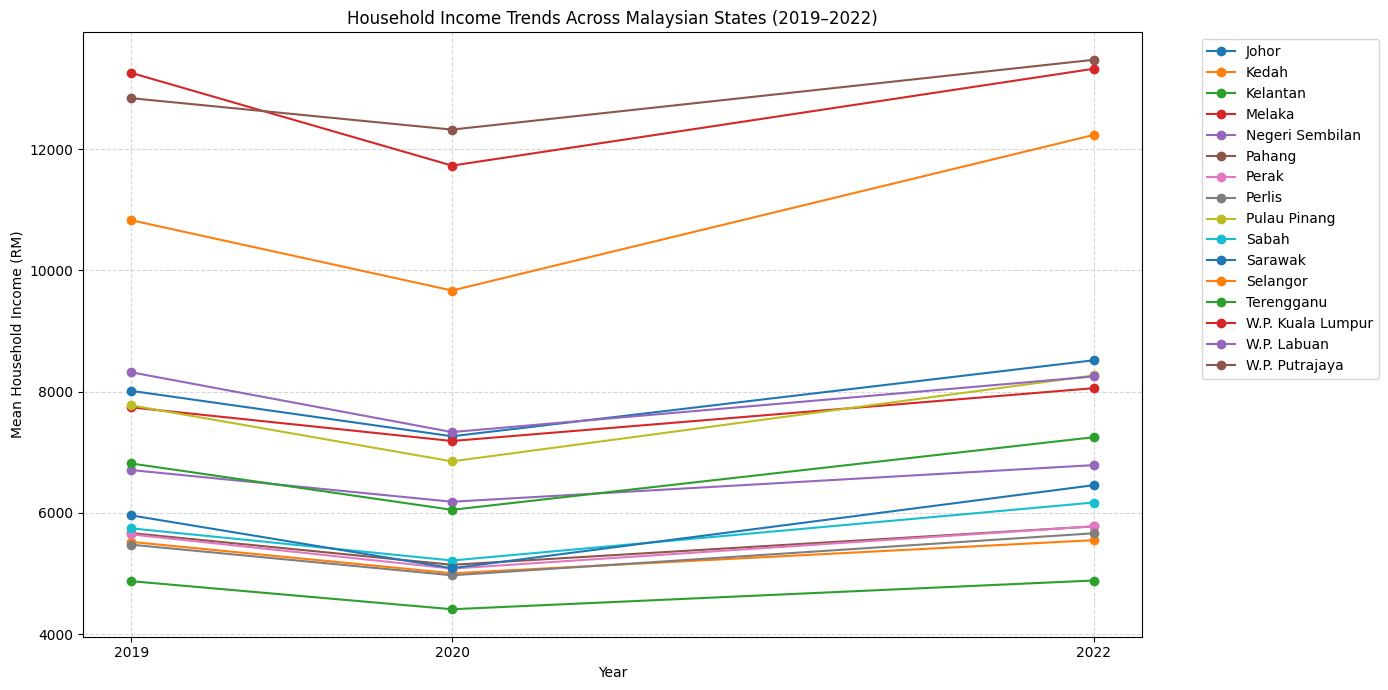

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 7))

for state in income_summary.index:
    plt.plot(
        income_summary.columns,
        income_summary.loc[state],
        marker='o',
        label=state
    )

plt.title('Household Income Trends Across Malaysian States (2019–2022)')
plt.xlabel('Year')
plt.ylabel('Mean Household Income (RM)')
plt.xticks([2019, 2020, 2022])
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

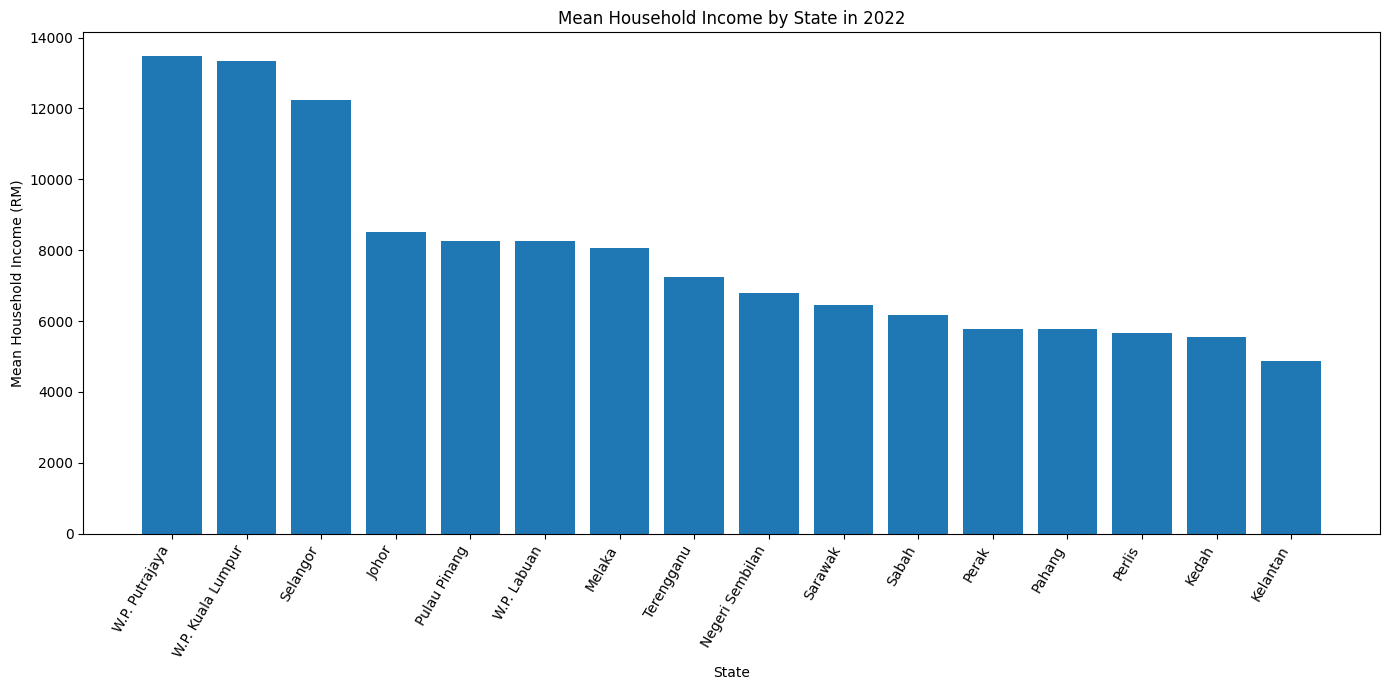

In [14]:
# Select household income data for 2022
income_2022 = income_clean[
    income_clean['date'].dt.year == 2022
].sort_values('income_mean', ascending=False)

plt.figure(figsize=(14, 7))

plt.bar(
    income_2022['state'],
    income_2022['income_mean']
)

plt.title('Mean Household Income by State in 2022')
plt.xlabel('State')
plt.ylabel('Mean Household Income (RM)')
plt.xticks(rotation=60, ha='right')

plt.tight_layout()
plt.show()

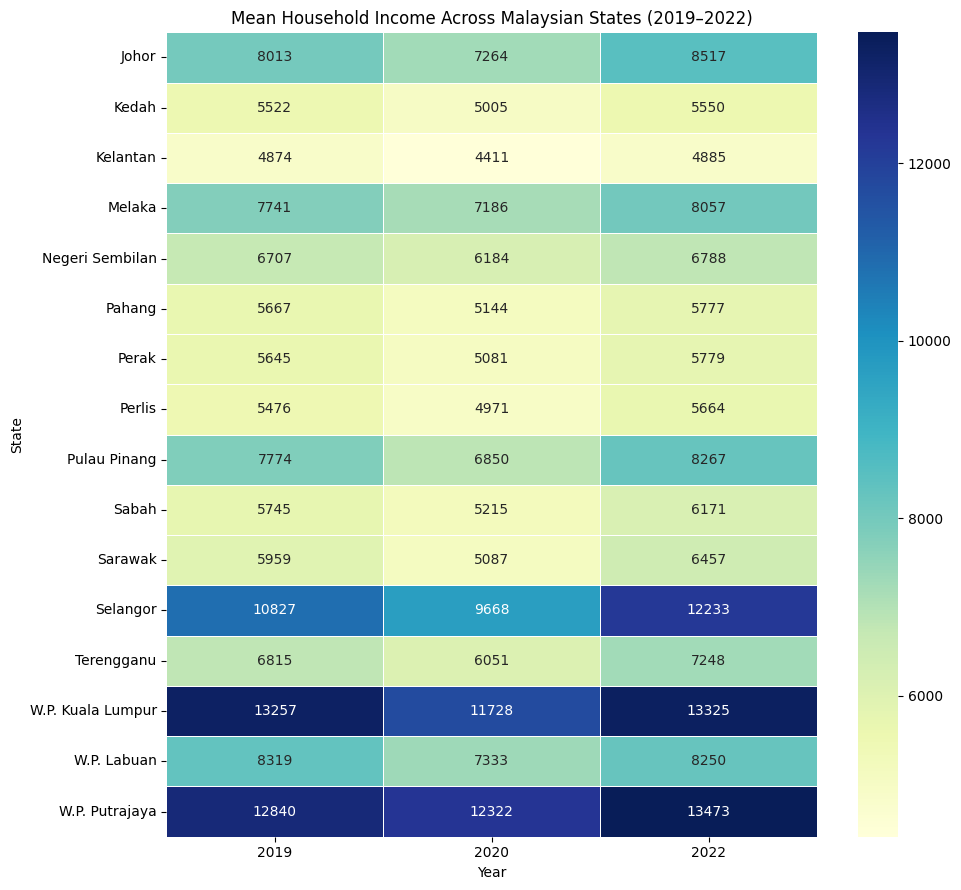

In [15]:
import seaborn as sns

plt.figure(figsize=(10, 9))

sns.heatmap(
    income_summary,
    annot=True,
    fmt='.0f',
    cmap='YlGnBu',
    linewidths=0.5
)

plt.title('Mean Household Income Across Malaysian States (2019–2022)')
plt.xlabel('Year')
plt.ylabel('State')

plt.tight_layout()
plt.show()

In [16]:
print("SCHOOL STAGES:")
print(sorted(schools_clean['stage'].unique()))

print("\nSCHOOL TYPES:")
print(sorted(schools_clean['type'].unique()))

print("\nNUMBER OF DISTRICTS:")
print(schools_clean['district'].nunique())

print("\nDISTRICT EXAMPLES:")
print(sorted(schools_clean['district'].unique())[:20])

SCHOOL STAGES:
['primary', 'secondary', 'tertiary']

SCHOOL TYPES:
['IPTA', 'Sekolah Menengah Kerajaan', 'Sekolah Rendah Kerajaan']

NUMBER OF DISTRICTS:
154

DISTRICT EXAMPLES:
['All Districts', 'Alor Gajah', 'Asajaya', 'Bachok', 'Bagan Datuk', 'Baling', 'Bandar Baharu', 'Barat Daya', 'Batang Padang', 'Batu Pahat', 'Bau', 'Beaufort', 'Belaga', 'Beluran', 'Bentong', 'Bera', 'Besut', 'Betong', 'Bintulu', 'Cameron Highlands']


In [17]:
print("ALL DISTRICTS RECORDS:")
display(
    schools_clean[
        schools_clean['district'] == 'All Districts'
    ].head(10)
)

print("\nNUMBER OF ALL DISTRICTS RECORDS:")
print(
    (schools_clean['district'] == 'All Districts').sum()
)

print("\nNUMBER OF INDIVIDUAL DISTRICTS:")
print(
    schools_clean[
        schools_clean['district'] != 'All Districts'
    ]['district'].nunique()
)

ALL DISTRICTS RECORDS:


,state,district,stage,type,date,schools
56,Johor,All Districts,primary,Sekolah Rendah Kerajaan,2019-01-01,907
57,Johor,All Districts,primary,Sekolah Rendah Kerajaan,2020-01-01,906
58,Johor,All Districts,primary,Sekolah Rendah Kerajaan,2021-01-01,906
59,Johor,All Districts,primary,Sekolah Rendah Kerajaan,2022-01-01,908
60,Johor,All Districts,primary,Sekolah Rendah Kerajaan,2023-06-30,908
65,Johor,All Districts,secondary,Sekolah Menengah Kerajaan,2019-01-01,282
66,Johor,All Districts,secondary,Sekolah Menengah Kerajaan,2020-01-01,283
67,Johor,All Districts,secondary,Sekolah Menengah Kerajaan,2021-01-01,284
68,Johor,All Districts,secondary,Sekolah Menengah Kerajaan,2022-01-01,284
69,Johor,All Districts,secondary,Sekolah Menengah Kerajaan,2023-06-30,284



NUMBER OF ALL DISTRICTS RECORDS:
240

NUMBER OF INDIVIDUAL DISTRICTS:
153


In [18]:
# State-level school records
schools_state = schools_clean[
    schools_clean['district'] == 'All Districts'
].copy()

# Individual district-level school records
schools_district = schools_clean[
    schools_clean['district'] != 'All Districts'
].copy()

print("State-level records:", schools_state.shape)
print("District-level records:", schools_district.shape)

State-level records: (240, 6)
District-level records: (2251, 6)


In [19]:
# Select state-level school records for 2022
schools_state_2022 = schools_state[
    schools_state['date'].dt.year == 2022
]

# Calculate total schools in each state
schools_by_state = (
    schools_state_2022
    .groupby('state')['schools']
    .sum()
    .sort_values(ascending=False)
)

display(schools_by_state)

,schools
state,
Sarawak,1459
Sabah,1297
Johor,1194
Perak,1106
Selangor,944
Kedah,753
Pahang,742
Kelantan,597
Terengganu,508


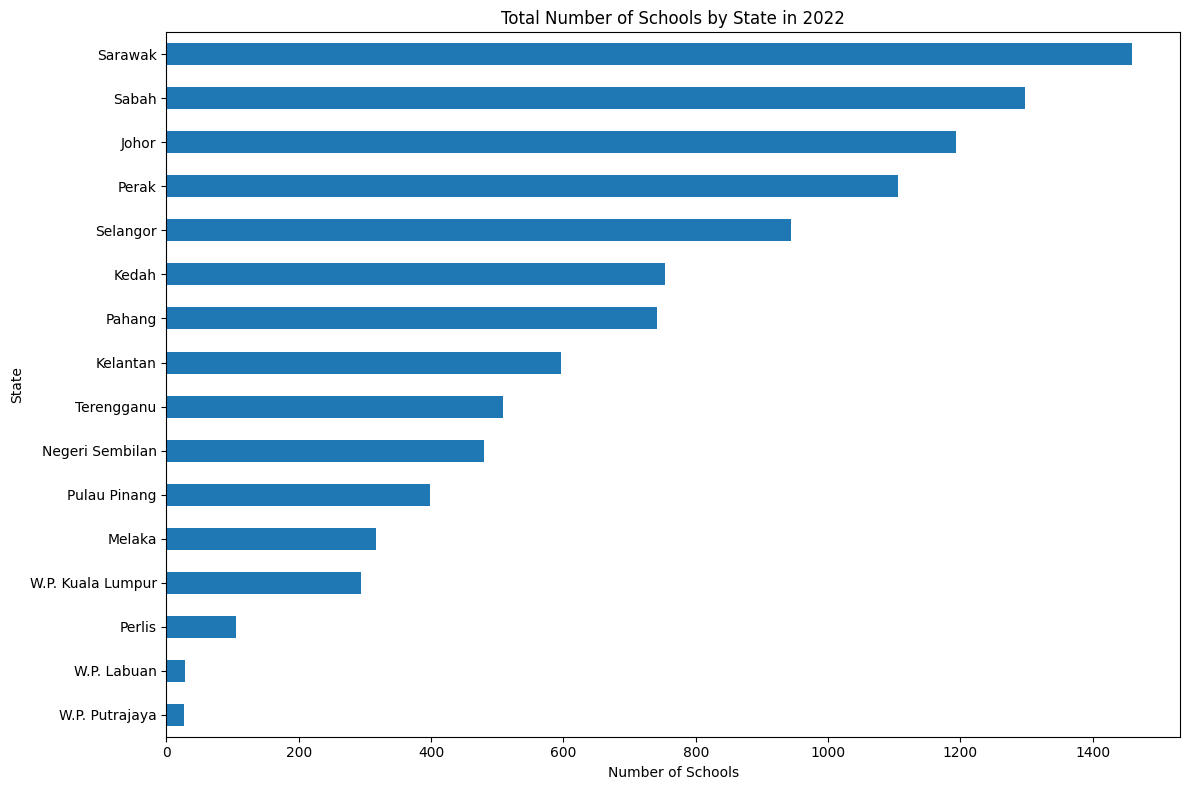

In [20]:
plt.figure(figsize=(12, 8))

schools_by_state.sort_values().plot(
    kind='barh'
)

plt.title('Total Number of Schools by State in 2022')
plt.xlabel('Number of Schools')
plt.ylabel('State')

plt.tight_layout()
plt.show()

In [21]:
# Select individual district records for 2022
schools_district_2022 = schools_district[
    schools_district['date'].dt.year == 2022
]

# Calculate total schools by district
schools_by_district = (
    schools_district_2022
    .groupby(['state', 'district'])['schools']
    .sum()
    .sort_values(ascending=False)
)

# Display the top 10 districts
display(schools_by_district.head(10))

,,schools
state,district,
W.P. Kuala Lumpur,W.P. Kuala Lumpur,294
Johor,Johor Bahru,271
Selangor,Petaling,226
Perak,Kinta,200
Sarawak,Kuching,188
Johor,Batu Pahat,177
Negeri Sembilan,Seremban,163
Perak,Larut Matang & Selama,147
Kelantan,Kota Bharu,146


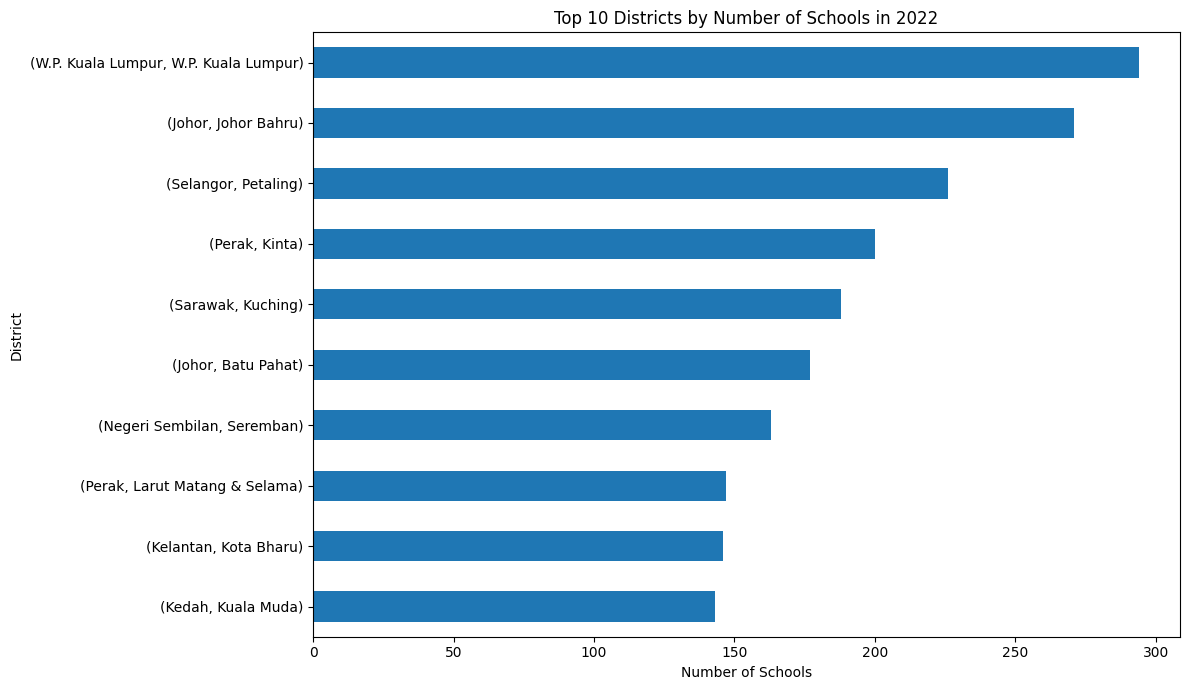

In [22]:
top_10_districts = schools_by_district.head(10).sort_values()

plt.figure(figsize=(12, 7))
top_10_districts.plot(kind='barh')

plt.title('Top 10 Districts by Number of Schools in 2022')
plt.xlabel('Number of Schools')
plt.ylabel('District')

plt.tight_layout()
plt.show()

In [23]:
# Extract the year
schools_state['year'] = schools_state['date'].dt.year

# Calculate total schools by year and school type
school_type_summary = (
    schools_state
    .groupby(['year', 'type'])['schools']
    .sum()
    .unstack()
)

display(school_type_summary)

type,IPTA,Sekolah Menengah Kerajaan,Sekolah Rendah Kerajaan
year,,,
2019,20,2439,7773
2020,20,2440,7780
2021,20,2444,7780
2022,20,2452,7778
2023,20,2452,7779


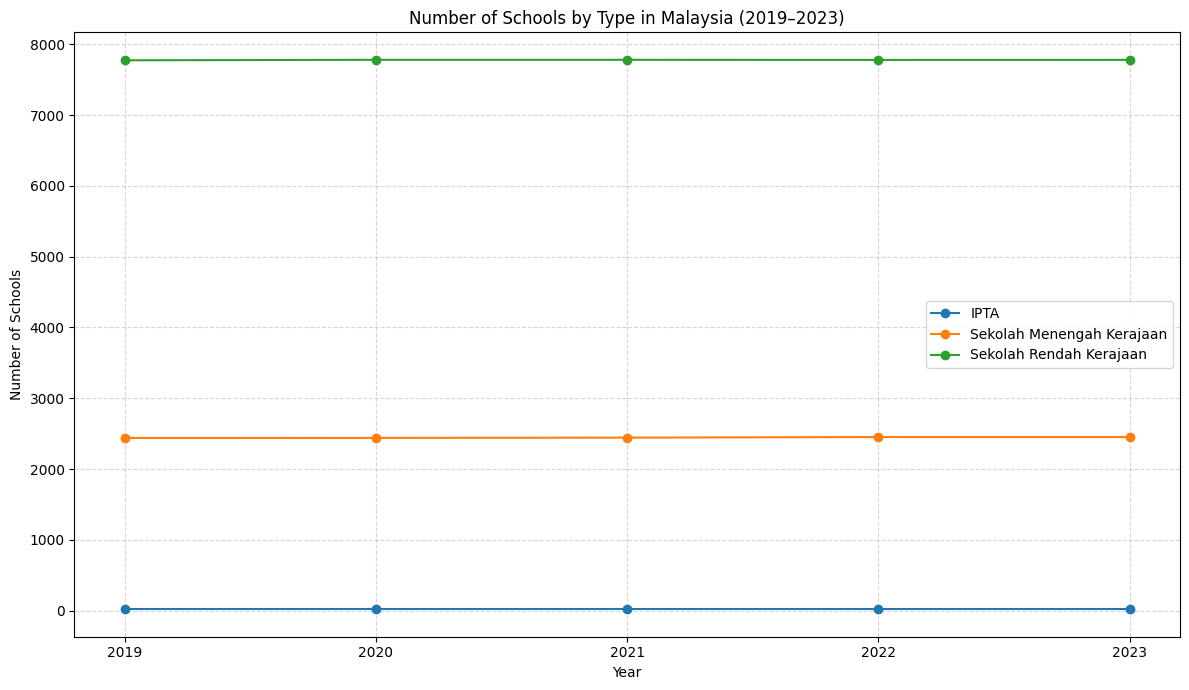

In [24]:
plt.figure(figsize=(12, 7))

for school_type in school_type_summary.columns:
    plt.plot(
        school_type_summary.index,
        school_type_summary[school_type],
        marker='o',
        label=school_type
    )

plt.title('Number of Schools by Type in Malaysia (2019–2023)')
plt.xlabel('Year')
plt.ylabel('Number of Schools')
plt.xticks([2019, 2020, 2021, 2022, 2023])
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [25]:
# Check the sex categories
print("Sex categories:")
print(marriages_clean['sex'].unique())

# Summarise marriages by year and sex
marriage_sex_summary = (
    marriages_clean
    .assign(year=marriages_clean['date'].dt.year)
    .groupby(['year', 'sex'])['abs']
    .sum()
    .unstack()
)

display(marriage_sex_summary)

Sex categories:
['female' 'male']


sex,female,male
year,,
2019,203661,203661
2020,184589,184589
2021,215973,215973
2022,214824,214824
2023,188100,188100


In [26]:
# Summarise marriage rates by year and sex
marriage_rate_summary = (
    marriages_clean
    .assign(year=marriages_clean['date'].dt.year)
    .groupby(['year', 'sex'])['rate']
    .mean()
    .unstack()
)

display(marriage_rate_summary)

sex,female,male
year,,
2019,24.58125,23.76250
2020,23.03125,22.48125
2021,26.10625,24.30625
2022,25.31250,23.23125
2023,21.87500,20.98750


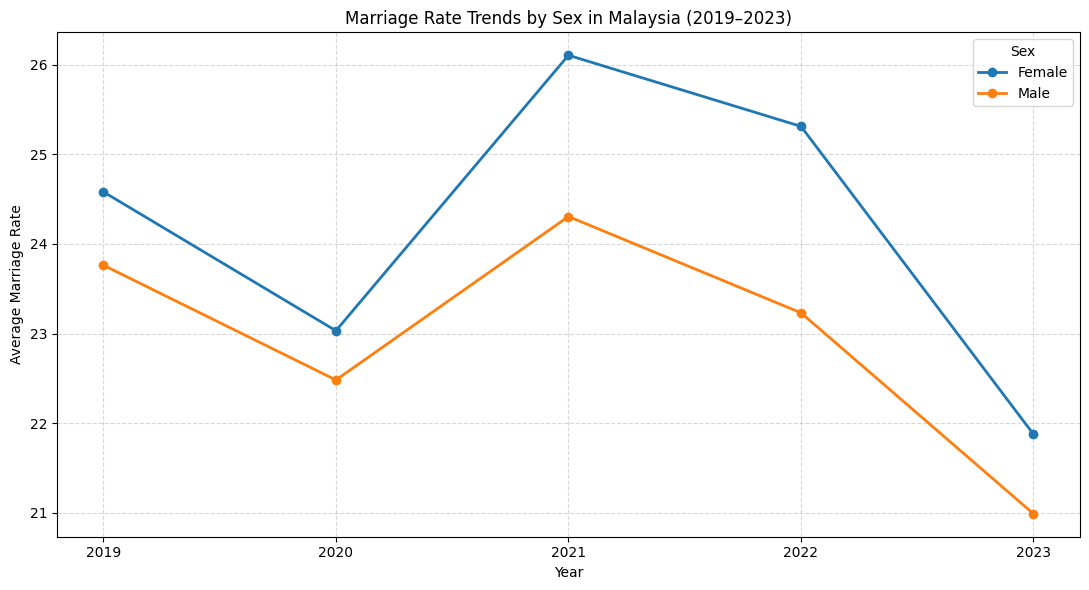

In [27]:
plt.figure(figsize=(11, 6))

for sex in marriage_rate_summary.columns:
    plt.plot(
        marriage_rate_summary.index,
        marriage_rate_summary[sex],
        marker='o',
        linewidth=2,
        label=sex.capitalize()
    )

plt.title('Marriage Rate Trends by Sex in Malaysia (2019–2023)')
plt.xlabel('Year')
plt.ylabel('Average Marriage Rate')
plt.xticks([2019, 2020, 2021, 2022, 2023])
plt.legend(title='Sex')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [28]:
# Filter marriage data for 2023
marriages_2023 = marriages_clean[
    marriages_clean['date'].dt.year == 2023
]

# Summarise marriage rates by state and sex
marriage_state_summary = (
    marriages_2023
    .pivot(index='state', columns='sex', values='rate')
)

display(marriage_state_summary)

sex,female,male
state,,
Johor,23.5,19.2
Kedah,26.4,21.1
Kelantan,26.4,29.2
Melaka,23.3,20.9
Negeri Sembilan,24.2,26.5
Pahang,22.7,18.6
Perak,23.6,30.8
Perlis,26.2,21.5
Pulau Pinang,18.5,17.6


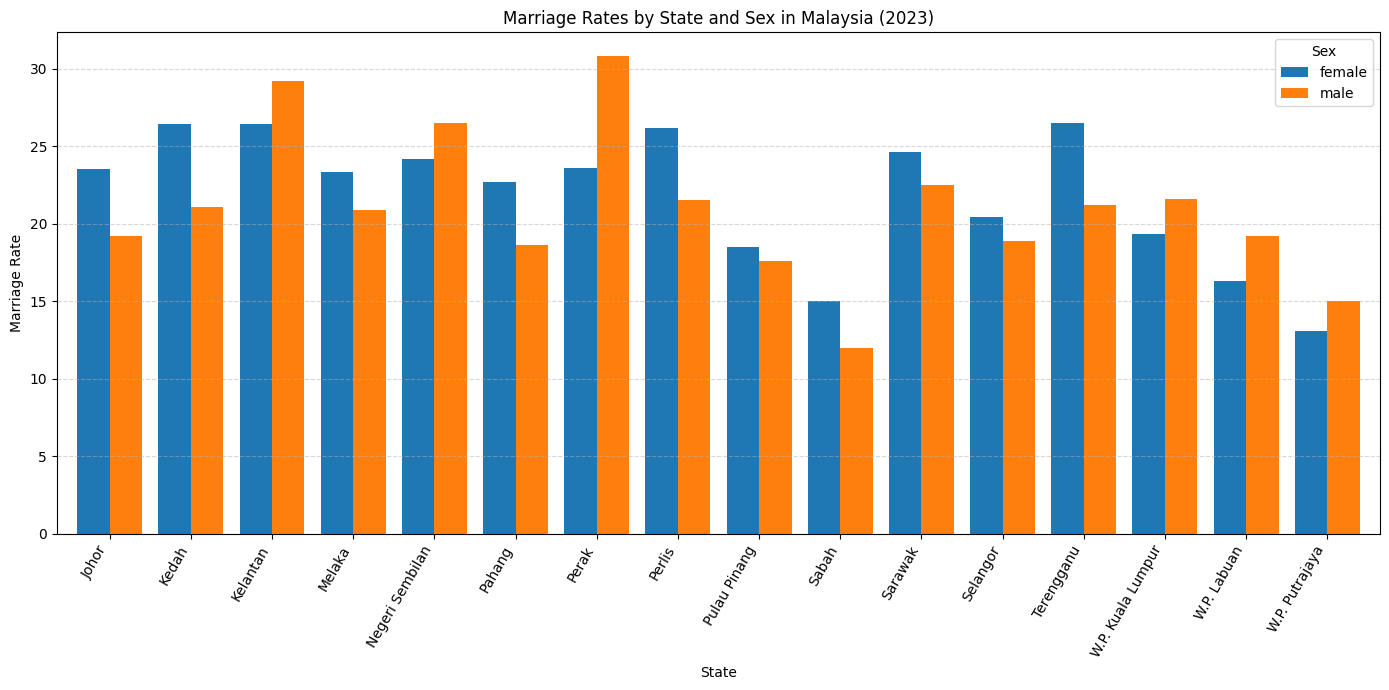

In [29]:
marriage_state_summary.plot(
    kind='bar',
    figsize=(14, 7),
    width=0.8
)

plt.title('Marriage Rates by State and Sex in Malaysia (2023)')
plt.xlabel('State')
plt.ylabel('Marriage Rate')
plt.xticks(rotation=60, ha='right')
plt.legend(title='Sex')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [30]:
# Prepare marriage rates by state and year
marriage_income = (
    marriages_clean
    .assign(year=marriages_clean['date'].dt.year)
    .groupby(['state', 'year'])['rate']
    .mean()
    .reset_index()
)

# Prepare household income by state and year
income_for_comparison = (
    income_clean
    .assign(year=income_clean['date'].dt.year)
    [['state', 'year', 'income_mean']]
)

# Combine marriage rates and household income
marriage_income = pd.merge(
    marriage_income,
    income_for_comparison,
    on=['state', 'year'],
    how='inner'
)

display(marriage_income.head(10))

print("Total records:", len(marriage_income))

,state,year,rate,income_mean
0,Johor,2019,25.75,8013
1,Johor,2020,22.10,7264
2,Johor,2022,23.45,8517
3,Kedah,2019,25.75,5522
4,Kedah,2020,26.40,5005
5,Kedah,2022,28.55,5550
6,Kelantan,2019,28.10,4874
7,Kelantan,2020,26.90,4411
8,Kelantan,2022,33.85,4885
9,Melaka,2019,27.60,7741


Total records: 48


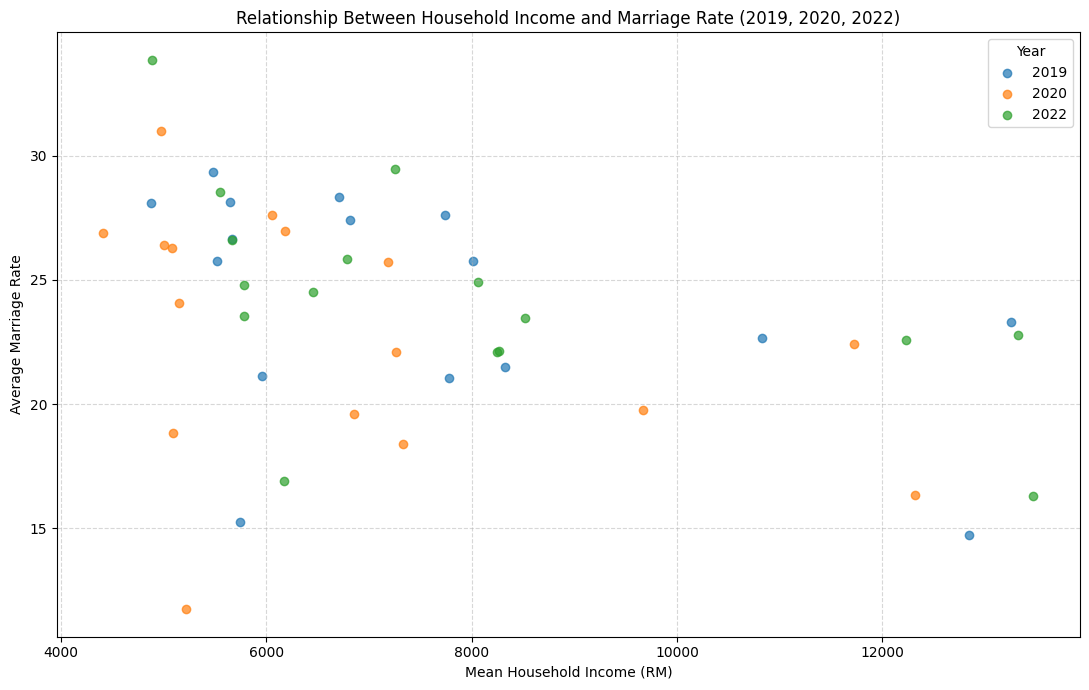

In [31]:
plt.figure(figsize=(11, 7))

for year in sorted(marriage_income['year'].unique()):
    year_data = marriage_income[
        marriage_income['year'] == year
    ]

    plt.scatter(
        year_data['income_mean'],
        year_data['rate'],
        label=str(year),
        alpha=0.7
    )

plt.title('Relationship Between Household Income and Marriage Rate (2019, 2020, 2022)')
plt.xlabel('Mean Household Income (RM)')
plt.ylabel('Average Marriage Rate')
plt.legend(title='Year')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [32]:
# Overall correlation
overall_correlation = marriage_income[
    'income_mean'
].corr(marriage_income['rate'])

print("Overall correlation:", round(overall_correlation, 3))

# Correlation for each year
yearly_correlation = (
    marriage_income
    .groupby('year')
    .apply(lambda group: group['income_mean'].corr(group['rate']))
)

print("\nCorrelation by year:")
display(yearly_correlation.round(3))

Overall correlation: -0.423

Correlation by year:


/tmp/ipykernel_2315/3004434749.py:12: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda group: group['income_mean'].corr(group['rate']))


,0
year,
2019,-0.469
2020,-0.379
2022,-0.547


In [33]:
plt.savefig('/content/charts/income_trends_by_state.png',
            dpi=300, bbox_inches='tight')


<Figure size 640x480 with 0 Axes>

/tmp/ipykernel_2315/919373266.py:1: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')


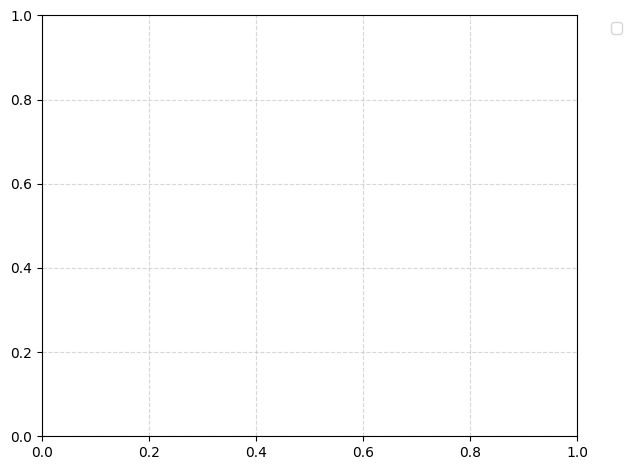

In [34]:
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()

plt.savefig('/content/charts/income_trends_by_state.png',
            dpi=300, bbox_inches='tight')

plt.show()

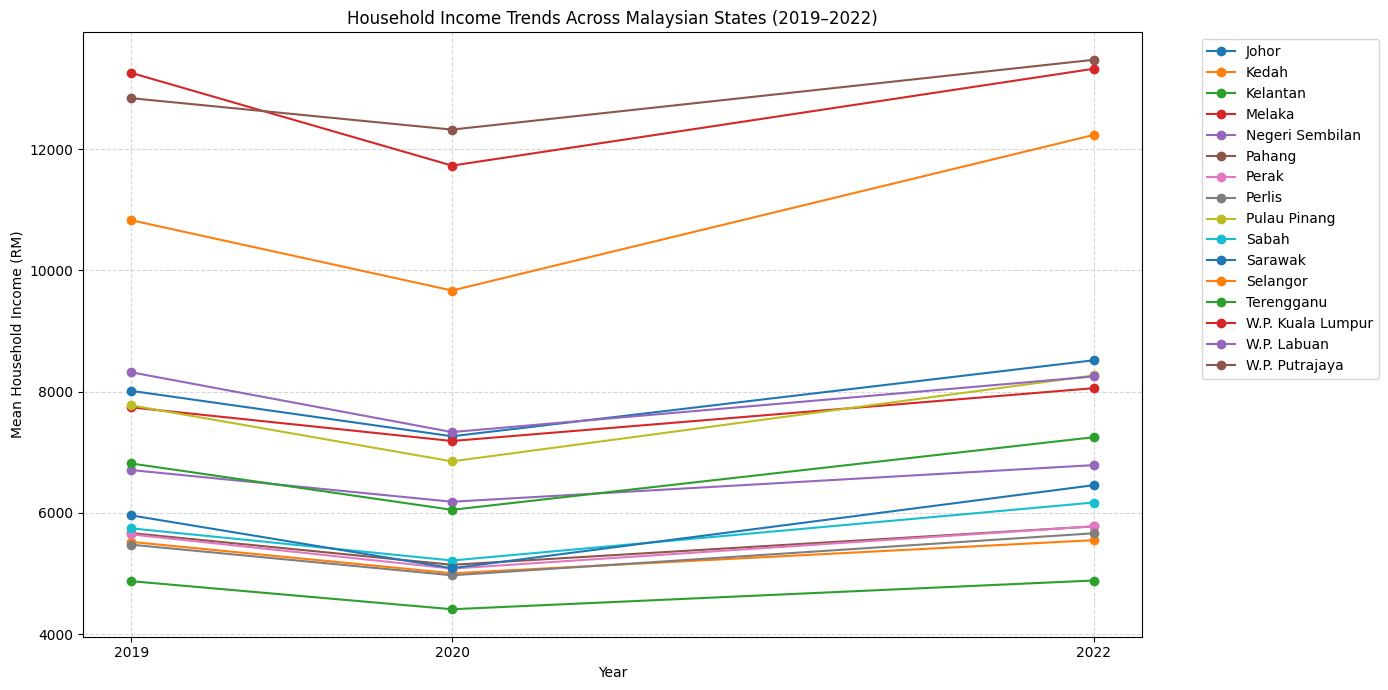

In [35]:
plt.figure(figsize=(14, 7))

for state in income_summary.index:
    plt.plot(
        income_summary.columns,
        income_summary.loc[state],
        marker='o',
        label=state
    )

plt.title('Household Income Trends Across Malaysian States (2019–2022)')
plt.xlabel('Year')
plt.ylabel('Mean Household Income (RM)')
plt.xticks([2019, 2020, 2022])

plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()

plt.savefig(
    '/content/charts/income_trends_by_state.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

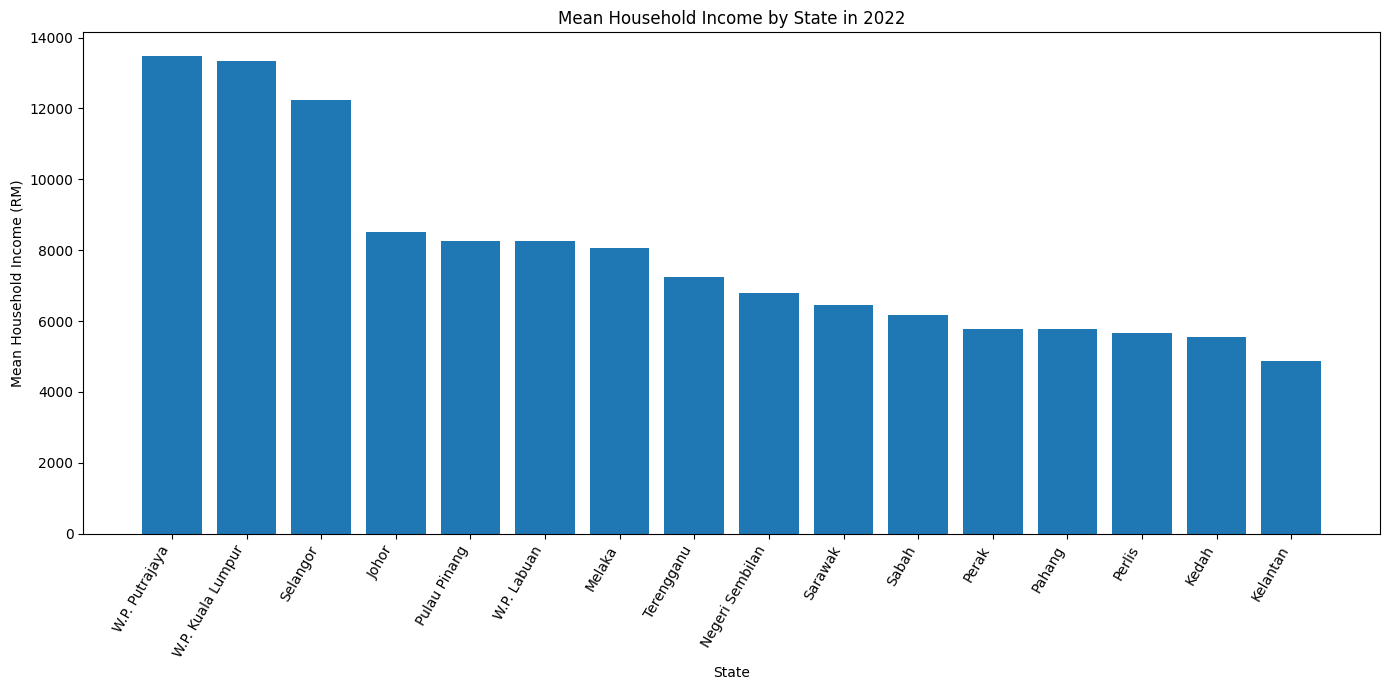

In [36]:
income_2022 = income_clean[
    income_clean['date'].dt.year == 2022
].sort_values('income_mean', ascending=False)

plt.figure(figsize=(14, 7))

plt.bar(income_2022['state'], income_2022['income_mean'])

plt.title('Mean Household Income by State in 2022')
plt.xlabel('State')
plt.ylabel('Mean Household Income (RM)')
plt.xticks(rotation=60, ha='right')

plt.tight_layout()

plt.savefig(
    '/content/charts/income_comparison_2022.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [37]:

import os
import matplotlib.pyplot as plt
import seaborn as sns

# Create charts folder if it does not exist
os.makedirs('/content/charts', exist_ok=True)

# =====================================
# OBJECTIVE 1: HOUSEHOLD INCOME
# =====================================

# Chart 1: Income trends by state
plt.figure(figsize=(14, 7))

for state in income_summary.index:
    plt.plot(
        income_summary.columns,
        income_summary.loc[state],
        marker='o',
        label=state
    )

plt.title('Household Income Trends Across Malaysian States (2019–2022)')
plt.xlabel('Year')
plt.ylabel('Mean Household Income (RM)')
plt.xticks([2019, 2020, 2022])
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('/content/charts/income_trends_by_state.png', dpi=300, bbox_inches='tight')
plt.close()

# Chart 2: Income comparison in 2022
income_2022 = income_clean[
    income_clean['date'].dt.year == 2022
].sort_values('income_mean', ascending=False)

plt.figure(figsize=(14, 7))
plt.bar(income_2022['state'], income_2022['income_mean'])
plt.title('Mean Household Income by State in 2022')
plt.xlabel('State')
plt.ylabel('Mean Household Income (RM)')
plt.xticks(rotation=60, ha='right')
plt.tight_layout()
plt.savefig('/content/charts/income_comparison_2022.png', dpi=300, bbox_inches='tight')
plt.close()

# Chart 3: Income heatmap
plt.figure(figsize=(10, 9))
sns.heatmap(
    income_summary,
    annot=True,
    fmt='.0f',
    cmap='YlGnBu',
    linewidths=0.5
)
plt.title('Mean Household Income Across Malaysian States (2019–2022)')
plt.xlabel('Year')
plt.ylabel('State')
plt.tight_layout()
plt.savefig('/content/charts/income_heatmap.png', dpi=300, bbox_inches='tight')
plt.close()


# =====================================
# OBJECTIVE 2: SCHOOL DISTRIBUTION
# =====================================

# Chart 4: Schools by state in 2022
plt.figure(figsize=(12, 8))
schools_by_state.sort_values().plot(kind='barh')
plt.title('Total Number of Schools by State in 2022')
plt.xlabel('Number of Schools')
plt.ylabel('State')
plt.tight_layout()
plt.savefig('/content/charts/schools_by_state.png', dpi=300, bbox_inches='tight')
plt.close()

# Chart 5: Top 10 districts
top_10_districts = schools_by_district.head(10).sort_values()

plt.figure(figsize=(12, 7))
top_10_districts.plot(kind='barh')
plt.title('Top 10 Districts by Number of Schools in 2022')
plt.xlabel('Number of Schools')
plt.ylabel('District')
plt.tight_layout()
plt.savefig('/content/charts/schools_by_district.png', dpi=300, bbox_inches='tight')
plt.close()

# Chart 6: Schools by type
plt.figure(figsize=(12, 7))

for school_type in school_type_summary.columns:
    plt.plot(
        school_type_summary.index,
        school_type_summary[school_type],
        marker='o',
        label=school_type
    )

plt.title('Number of Schools by Type in Malaysia (2019–2023)')
plt.xlabel('Year')
plt.ylabel('Number of Schools')
plt.xticks([2019, 2020, 2021, 2022, 2023])
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('/content/charts/schools_by_type.png', dpi=300, bbox_inches='tight')
plt.close()


# =====================================
# OBJECTIVE 3: MARRIAGE TRENDS
# =====================================

# Chart 7: Marriage rates by sex
plt.figure(figsize=(11, 6))

for sex in marriage_rate_summary.columns:
    plt.plot(
        marriage_rate_summary.index,
        marriage_rate_summary[sex],
        marker='o',
        linewidth=2,
        label=sex.capitalize()
    )

plt.title('Marriage Rate Trends by Sex in Malaysia (2019–2023)')
plt.xlabel('Year')
plt.ylabel('Average Marriage Rate')
plt.xticks([2019, 2020, 2021, 2022, 2023])
plt.legend(title='Sex')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('/content/charts/marriage_trends_by_sex.png', dpi=300, bbox_inches='tight')
plt.close()

# Chart 8: Marriage rates by state and sex in 2023
marriage_state_summary.plot(
    kind='bar',
    figsize=(14, 7),
    width=0.8
)

plt.title('Marriage Rates by State and Sex in Malaysia (2023)')
plt.xlabel('State')
plt.ylabel('Marriage Rate')
plt.xticks(rotation=60, ha='right')
plt.legend(title='Sex')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('/content/charts/marriage_by_state_and_sex.png', dpi=300, bbox_inches='tight')
plt.close()

# Chart 9: Income and marriage rate relationship
plt.figure(figsize=(11, 7))

for year in sorted(marriage_income['year'].unique()):
    year_data = marriage_income[
        marriage_income['year'] == year
    ]

    plt.scatter(
        year_data['income_mean'],
        year_data['rate'],
        label=str(year),
        alpha=0.7
    )

plt.title('Relationship Between Household Income and Marriage Rate (2019, 2020, 2022)')
plt.xlabel('Mean Household Income (RM)')
plt.ylabel('Average Marriage Rate')
plt.legend(title='Year')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('/content/charts/income_and_marriage_relationship.png', dpi=300, bbox_inches='tight')
plt.close()


# =====================================
# VERIFY ALL SAVED CHARTS
# =====================================

print("All charts have been saved successfully!")

chart_files = sorted(os.listdir('/content/charts'))

for i, filename in enumerate(chart_files, start=1):
    print(f"{i}. {filename}")

print("\nTotal chart images:", len(chart_files))


All charts have been saved successfully!
1. income_and_marriage_relationship.png
2. income_comparison_2022.png
3. income_heatmap.png
4. income_trends_by_state.png
5. marriage_by_state_and_sex.png
6. marriage_trends_by_sex.png
7. schools_by_district.png
8. schools_by_state.png
9. schools_by_type.png

Total chart images: 9


In [38]:
import shutil
from google.colab import files

# Create ZIP file containing all 9 charts
shutil.make_archive(
    '/content/all_visualization_charts',
    'zip',
    '/content/charts'
)

# Download ZIP file
files.download('/content/all_visualization_charts.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>